In [1]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import warnings


In [2]:
df=pd.read_csv("Child_mortality_cross_sectional.csv")
df.head(10)
# df.isnull

,Observation,CM,FLFP,PGNP,TFR
0,1,128,37,1870,6.66
1,2,204,22,130,6.15
2,3,202,16,310,7.00
3,4,197,65,570,6.25
4,5,96,76,2050,3.81
5,6,209,26,200,6.44
6,7,170,45,670,6.19
7,8,240,29,300,5.89
8,9,241,11,120,5.89
9,10,55,55,290,2.36


In [3]:
df.shape

(64, 5)

In [4]:
df.columns


Index(['Observation', 'CM', 'FLFP', 'PGNP', 'TFR'], dtype='object')

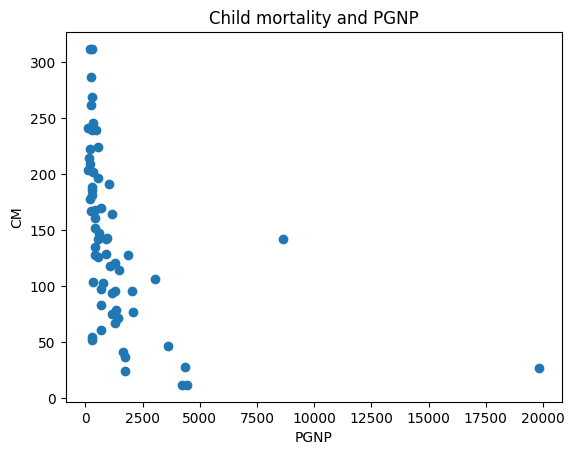

In [5]:
## Plotting scatter plot CM vs Per capita GNP
plt.scatter(df.PGNP,df.CM)
plt.xlabel("PGNP")
plt.ylabel("CM")
plt.title("Child mortality and PGNP")
plt.show()


In [6]:
 # Comment:The slope of Eq. (6.7.1) is: dY /dX = −β2(1/X2), implying that if β2 is positive, the slope is
# negative throughout, and if β2 is negative, the slope is positive throughout

## Here we try to fit reciprocal model

In [7]:
from scipy import stats
x=df.PGNP
y=df.CM

In [8]:
slope, intercept, r, p, std_err=stats.linregress(x,y)
def reciprocal(x):
    return slope*(1/x) + intercept
    
print("Slope",slope)
print("Intercept of the regression",intercept)
print("r_square",r)

Slope -0.011363155017932015
Intercept of the regression 157.42084547590568
r_square -0.4076242503066871


## Partial regression

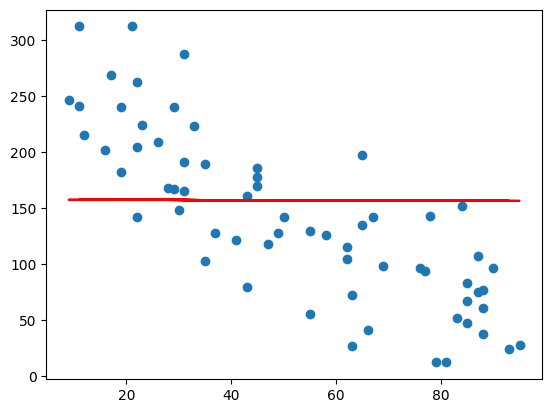

In [16]:
x1=df.FLFP
slope, intercept, r, p, std_err=stats.linregress(x,y)
def linflfp(x1):
    return slope*x1 + intercept

mymodel = list(map(linflfp, x1))

plt.scatter(x1, y)
plt.plot(x1, mymodel,color='red')
plt.show()

## Child Mortality in Relation toper Capita GNP and Female Literacy Rate

In [10]:
x2=df[["FLFP","PGNP"]]
from sklearn import linear_model
from sklearn import metrics
reg_model=linear_model.LinearRegression()
reg_model.fit(x2,y)

LinearRegression()

In [11]:
print("slopes",reg_model.coef_)

slopes [-2.20552414 -0.00571883]


In [12]:
r_square=reg_model.score(x2,y)
print("coefficient of determination",r_square)


coefficient of determination 0.7041610278191694


In [13]:
# Intercept
print("Intercept",reg_model.intercept_)

Intercept 262.75249823713153


In [14]:
# now here we are predicting the response variable(Child mortality)

y_pred=reg_model.predict(x2)
print('Predicted response:', y_pred[:5], sep='\n')

Predicted response:
[170.45389134 213.48751915 225.69127443 116.13369557  83.40906034]


In [1]:
# reg_model.summary()
# Comment: